In [1]:
# =============================================
# IMPORT
# =============================================
from utility.logger         import aiLogger
from keras.callbacks        import EarlyStopping, ReduceLROnPlateau
from model.componentModel   import mainModel
from model.tepSystemModel   import SystemModel
from preProcessingDataTEP   import PreProcessData
from prettytable            import PrettyTable

from keras.optimizers       import Adam
from utility.matpilotDraw   import MatPlot
from sklearn.preprocessing  import MinMaxScaler

import tensorflow           as tf
import pandas               as pd
import matplotlib.pyplot    as plt
import numpy                as np
import os, warnings
import random
import json


2025-06-11 16:53:54.720438: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-06-11 16:53:54.862838: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-06-11 16:53:55.543452: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/home/ducan/anaconda3/envs/tensorflow2.10.0Crusher/lib/
2025-06-11 16:53:55.543547: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerro

### Evaluation code

In [2]:
# ==============================
#           MONOTONICITY
# ==============================
def proportion_based_monotonicity(hi_series, segment_size=32):
    """
    Calculate proportion-based monotonicity using segments.

    Parameters:
        hi_series (pd.Series)   : Health indicator series (e.g., HI values over time).
        segment_size (int)      : Size of each segment.

    Returns:
        float                   : Proportion-based monotonicity (range 0 to 1).
    """
    hi_series = hi_series.dropna()  # Remove NaN values
    
    if len(hi_series) < segment_size * 2:
        raise ValueError("Not enough data to calculate monotonicity with the specified segment size.")

    # ----------------------------------
    # Step 1: Divide the data into segments
    # and calculate the mean of each segment
    # -----------------------------------
    num_segments    = len(hi_series) // segment_size
    aggregated      = [hi_series.iloc[i * segment_size:(i + 1) * segment_size].mean() for i in range(num_segments)]


    # ----------------------------------
    # Step 2: Calculate the proportion
    # of consistent steps
    # ----------------------------------
    diffs           = pd.Series(aggregated).diff().dropna()  # Calculate differences between segments
    positive_steps  = (diffs > 0).sum()
    negative_steps  = (diffs < 0).sum()

    # ----------------------------------
    # Step 3: Calculate monotonicity as
    # the proportion of consistent steps
    # ----------------------------------
    total_steps = len(diffs)
    monotonicity = abs((positive_steps - negative_steps) / total_steps)  # Normalize to 0-1
    return monotonicity

def calculate_monotonicity(hi_series: pd.Series) -> float:
    """
    Calculate a single‐trajectory monotonicity:
        Mon = |#(∆HI > 0) − # (∆HI < 0)|  /  (n − 1)

    Parameters:
        hi_series (pd.Series): A single HI trajectory (ordered by time).

    Returns:
        float: Monotonicity in [0, 1].
    """
    hi_series = hi_series.dropna()
    n = len(hi_series)
    if n < 2:
        return 0.0

    # Compute first differences
    diffs = hi_series.diff().dropna()
    pos_steps = (diffs > 0).sum()
    neg_steps = (diffs < 0).sum()

    return abs(pos_steps - neg_steps) / (n - 1)


# ==============================
#           ROBUSTNESS
# ==============================
def calculate_robustness_polyfit(hi_series, degree=25):
    """
    Calculate robustness using polynomial fitting for trend estimation.

    Parameters:
        hi_series (pd.Series)   : Health indicator series (e.g., HI values over time).
        degree (int)            : Degree of the polynomial for trend fitting.

    Returns:
        float                   : Robustness score (range 0 to 1).
    """
    hi_series   = hi_series.dropna()  # Remove NaN values
    n           = len(hi_series)
    if n < degree + 1:
        return 0.0  # Not enough data to fit the polynomial

    # --------------------------------
    # Step 1: Fit a polynomial trend
    # --------------------------------
    x               = np.arange(n)
    y               = hi_series.values
    poly_coeffs     = np.polyfit(x, y, degree)  # Fit polynomial
    poly_trend      = np.polyval(poly_coeffs, x)  # Evaluate polynomial trend

    # --------------------------------
    # Step 2: Calculate deviations and 
    # normalize by standard deviation
    # --------------------------------
    deviations      = abs(hi_series - poly_trend)
    std_dev         = hi_series.std()
    if std_dev == 0:
        return 1.0  # Perfect stability, no variance

    normalized_deviations = deviations / std_dev

    # --------------------------------
    # Step 3: Compute robustness
    # --------------------------------
    robustness      = np.exp(-normalized_deviations.mean())
    return robustness

def chunked_robustness(hi_series, chunk_size =10):
    hi_series = hi_series.dropna().reset_index(drop=True)
    n = len(hi_series)
    if n < chunk_size * 2:
        return 0.0

    num_chunks = n // chunk_size
    chunk_means = [hi_series[i * chunk_size:(i + 1) * chunk_size].mean()
                   for i in range(num_chunks)]
    
    chunk_series = pd.Series(chunk_means)
    std = chunk_series.std()
    if std <= 1e-7:
        return 1.0  # perfect stability
    
    norm_diff = np.abs((chunk_series - chunk_series.mean()) / std)
    return np.exp(-norm_diff.mean())



def robustness_single_hi(hi_series: pd.Series) -> float:
    """
    Calculate robustness for a single health indicator series.

    Parameters:
        hi_series (pd.Series): A single health indicator trajectory.

    Returns:
        float: Robustness value in [0, 1].
    """

    hi_series = hi_series.dropna()
    if len(hi_series) == 0:
        raise ValueError("Input series is empty after dropping NaN values.")

    std = hi_series.std()
    if std <= 1e-7:
        raise ValueError("Standard deviation is too small, indicating no variability in the series.")

    mean_hi             = hi_series.mean()
    normalized_diff     = np.abs((hi_series - mean_hi) / std)
    rob                 = np.exp(-normalized_diff.mean())
    return rob


# ==============================
#           TRENDABILITY
# ==============================
def calculate_trendability(hi_series, time=None, time_step=0.5):
    """
    Calculate trendability using the absolute Pearson correlation between time and HI,
    based on the interpretation in the referenced paper.

    Parameters:
        hi_series (pd.Series): Health indicator series (e.g., HI values over time).
        time (array-like, optional): Time values aligned with the series.
        time_step (float): Used to generate uniform time if 'time' is not provided.

    Returns:
        float: Trendability score in [0, 1].
    """
    time = None
    hi_series = hi_series.dropna()
    n = len(hi_series)
    if n < 2:
        raise ValueError("Not enough data to calculate trendability.")

    time = np.arange(n) * time_step if time is None else np.array(time)
    if len(time) != n:
        raise ValueError("Time and HI series must be of the same length.")

    correlation = np.corrcoef(time, hi_series)[0, 1]
    return abs(correlation)


# ---------------------------------------
# Compute robustness, trendability, 
# and monotonicity for a single HI trajectory.
# ---------------------------------------
def compute_hi_metrics_for_id(df: pd.DataFrame, hiCol = "HI") -> dict:
    """
    Parameters:
        df (pd.DataFrame): DataFrame with 'cycle' and 'HI' columns for one engine ID.

    Returns:
        dict: Dictionary with metrics.
    """
    # hi_series = df.sort_values("cycle")["HI"]
    hi_series = df[hiCol]
    try:
        robustness = chunked_robustness(hi_series)
    except ValueError:
        robustness = np.nan

    try:
        trendability = calculate_trendability(hi_series, time = df["cycle"])
    except ValueError:
        trendability = np.nan

    try:
        monotonicity = proportion_based_monotonicity(hi_series)
        # print(f"Monotonicity for ID {df['id'].iloc[0]}: {monotonicity}")
    except ValueError:
        monotonicity = np.nan

    return {
        "robustness": robustness,
        "trendability": trendability,
        "monotonicity": monotonicity
    }

# ---------------------------------------
# Compute the average robustness, trendability, 
# and monotonicity over all HI trajectories.
# ---------------------------------------
def compute_average_hi_metrics(dfHI, hiCol = "HI"):
    """
    Parameters:
        dfHI (pd.DataFrame): DataFrame with columns 'id', 'cycle', and 'HI'.

    Returns:
        dict: Dictionary with average metric values.
    """
    grouped         = dfHI.groupby("id")
    metrics_list    = [compute_hi_metrics_for_id(group, hiCol) for _, group in grouped]

    # Convert to DataFrame for easy averaging and NaN handling
    metrics_df      = pd.DataFrame(metrics_list)

    return {
        "avg_robustness": metrics_df["robustness"].mean(),
        "avg_trendability": metrics_df["trendability"].mean(),
        "avg_monotonicity": metrics_df["monotonicity"].mean()
    }



In [3]:
# ---------------------------
# Loading config file
# ---------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    configData = json.load(configFile)
config = configData["tep"]  

# ---------------------------
# Set debug level and 
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 
np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

outputDir               = os.path.expanduser(config["dataDir"])
totalTraject            = 100
normalizeHI             = True
showRedundantShutdown   = False

#### Preprocessing data

In [4]:
# ==============================
# Config and data preprocessing
# ==============================
preData             = PreProcessData(config=config)
rawData             = preData.loadDataFromH5Format(dir              = outputDir, 
                                                   name             = "data/teps.h5",
                                                   case             = "all", 
                                                   reduceSampleRate = True, 
                                                   removeHigherThr  = False)

withRULData         = preData.addRULAndEnvironment(rawData)
# withoutInitRawData  = preData.removeInitState(inData= withRULData)



# ---------------------------
# For data
cleanData           = preData.cleanData(rawSignal           =   withRULData,
                                        columnName          =   preData.allWithoutLabel,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
# ---------------------------
# For label, flip only
cleanData           = preData.cleanData(rawSignal           =   cleanData,
                                        columnName          =   preData.degraLiq,
                                        getMovingAverage    =   False,
                                        flipToDown          =   False)
norData             = preData.normalizeDataEachModes(rawData    = cleanData,
                                                     headline   =   preData.headline["allWithoutLabelNoBias"])    # Normalize the data



Process:58525||2025-06-11 16:53:57,210-INFO [preProcessingDataTEP.py:loadDataFromH5Format():357]:Loading data from H5 files ...
Process:58525||2025-06-11 16:53:58,222-INFO [preProcessingDataTEP.py:loadDataFromH5Format():384]:Finish loading data from H5 files at case all...
Process:58525||2025-06-11 16:53:58,452-INFO [preProcessingDataTEP.py:addRULAndEnvironment():433]:Adding rul successfully...
Process:58525||2025-06-11 16:53:58,452-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:58525||2025-06-11 16:53:58,453-INFO [preProcessingDataTEP.py:cleanData():510]:Cleaning data ...
Process:58525||2025-06-11 16:53:58,453-INFO [preProcessingDataTEP.py:normalizeDataEachModes():800]:Normalizing the data ...


In [5]:
# curCase     = 2
# caseData    = rawData[curCase]
# aiLogger.debug(f"------------------------- The case {curCase}")

# for idx in range(100):
#     curId = idx + 1
    
#     # Filter data directly for the current Id
#     curData = caseData[caseData["Id"] == curId]
    
#     if not curData.empty:
#         # Safely access the last value of "Stripper Level"
#         print(curData["Stripper Level"].iloc[-1])
#     else:
#         print(f"Id {curId} not found in the data")

#### Declare the model

In [6]:
# config["component"] = "Reac"
# vaeReac = mainModel(config = config)
# vaeReac.build(input_shape=[(None, config["seqLength"], config["inReac"]), (None, 1, config["inReac"]), (None, 1)])
# # vaeReac.build(input_shape=(None, config["seqLength"], config["inReac"]))
# vaeReac.summary()
# vaeReac.load_weights(outputDir + "checkpoint/bestModel30Reac/")

In [7]:
# config["component"] = "Sep"
# vaeSep = mainModel(config = config)
# vaeSep.build(input_shape=[(None, config["seqLength"], config["inSep"]), (None, 1, config["inSep"]), (None, 1)])
# vaeSep.summary()
# vaeSep.load_weights(outputDir + "checkpoint/bestModel31Sep/")

In [8]:
# config["component"] = "Strip"
# vaeStrip = mainModel(config = config)
# vaeStrip.build(input_shape=[(None, config["seqLength"], config["inStrip"]), (None, 1, config["inStrip"]), (None, 1)])
# vaeStrip.summary()
# vaeStrip.load_weights(outputDir + "checkpoint/bestModel32Strip/")

In [9]:
config["component"] = "Sys"
vaeSys = SystemModel(config = config)
vaeSys.build(input_shape=[(None, config["seqLength"], config["inReac"]), (None, 1, config["inReac"]), (None, 1)])
vaeSys.summary()

modelDirComp1 = outputDir + "checkpoint/" + "bestModel34Reac"
modelDirComp2 = outputDir + "checkpoint/" + "bestModel35Sep"
modelDirComp3 = outputDir + "checkpoint/" + "bestModel36Strip"
modelDirSys   = outputDir + "checkpoint/" + "bestModel38Sys"
vaeSys.load_weights(modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys)

2025-06-11 16:54:01.098272: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-06-11 16:54:01.110677: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-06-11 16:54:01.111046: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-06-11 16:54:01.111856: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:58525||2025-06-11 16:54:02,974-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():923]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip


The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:58525||2025-06-11 16:54:03,012-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():962]:Loaded the model at the direction:('/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac', '/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep', '/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip') and freezed it successfully!!!
Process:58525||2025-06-11 16:54:03,028-DEBUG [tepSystemModel.py:__init__():313]:The shape of hiSelectionInput (None, 120)
Process:58525||2025-06-11 16:54:03,059-DEBUG [tepSystemModel.py:__init__():321]:The shape of multiplied matrix (None, 3)
Process:58525||2025-06-11 16:54:03,076-DEBUG [tepSystemModel.py:__init__():331]:The shape of min, max and linear HI (TensorShape([None, 1]), TensorShape([None, 1]), TensorShape([None, 1]))
Process:58525||2025-06-11 16:54:03,079-DEBUG [tepSystemModel.py:__init__():334]:The shape after concatenation (None, 3)
Process:58525||2025-06-11

-------------------------------
(3, 45)
(None, 1, 45)
(None, 128, 45)
(None, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(None, 1, 45)
(None, 128, 45)
(None, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(None, 1, 45)
(None, 128, 45)
(None, 128, 45)
-------------------------------
Model: "system_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sensor_selection (SensorSel  multiple                 135       
 ection)                                                         
                                                                 
 sensor_selection_1 (SensorS  multiple                 135       
 election)                                                       
                                                                 
 sensor_selection_2 (SensorS  multiple                 135       
 election)                    

Process:58525||2025-06-11 16:54:04,424-INFO [tepSystemModel.py:load_weights():888]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel38Sys
Process:58525||2025-06-11 16:54:04,465-INFO [tepSystemModel.py:load_weights():920]:Loaded the model at the direction:/home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/codeData/tepDataWithoutGit/checkpoint/bestModel38Sys successfully!!!


### MAKS EACH COMPONENT IN EACH ENVIRONMENT

#### Reactor

In [10]:
binaryMaskReac, probsReac     = vaeSys.maskCr1.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 26.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         |      1.0      |  1.0   |
| 1  |         A Feed         | 1.0593292e-12 |  0.0   |
| 2  |      A and C Feed      |      1.0      |  1.0   |
| 3  |         Purge          |      1.0      |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        |      1.0      |  1.0   |
| 6  |    Reactor Coolant     | 1.0623663e-12 |  0.0   |
| 7  |   Condenser Coolant    |  1.065079e-12 |  0.0   |
| 8  |       msv A Feed       |  1.059976e-12 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       |      1.0      |  1.0   |
| 11 |    msv A and C Feed    |      1.0      |  1.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Separator

In [11]:
binaryMaskReac, probsReac     = vaeSys.maskCr2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)



The number of selected sensor in the environment 1 is 13.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 4.6886475e-13 |  0.0   |
| 1  |         A Feed         | 4.6633183e-13 |  0.0   |
| 2  |      A and C Feed      | 4.6340227e-13 |  0.0   |
| 3  |         Purge          | 4.6123657e-13 |  0.0   |
| 4  |       Separator        |  4.627496e-13 |  0.0   |
| 5  |        Stripper        |      1.0      |  1.0   |
| 6  |    Reactor Coolant     | 4.5894007e-13 |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 4.6479915e-13 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       | 4.6254927e-13 |  0.0   |
| 11 |    msv A and C Feed    | 4.5658963e-13 |  0.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Stripper

In [12]:
binaryMaskReac, probsReac     = vaeSys.maskCv2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 19.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 1.7232655e-13 |  0.0   |
| 1  |         A Feed         |  1.670584e-13 |  0.0   |
| 2  |      A and C Feed      | 1.9034903e-13 |  0.0   |
| 3  |         Purge          |      1.0      |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        | 1.9865823e-13 |  0.0   |
| 6  |    Reactor Coolant     | 1.6826333e-13 |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 1.6601526e-13 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       | 1.6638454e-13 |  0.0   |
| 11 |    msv A and C Feed    | 1.7078405e-13 |  0.0   |
| 12 |      Recycle Flow      | 1.5469925e-13 |  0.0   |
| 13 |   Reactor Feed Rate   

### HI FOR EACH ENVIRONMENT

#### Environment 2

In [13]:
environmentIdx      = 2
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []
labelRUL            = []
predictRUL         = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]


    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # aiLogger.debug(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    labelRUL.append(seqXRulTrain[:,-1,:])
    predictRUL.append(predictedRul)
    # print("---------------======================")
    # print(predictedRul.shape)
    # print(seqXRulTrain[:,-1,:].shape)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

# aiLogger.debug((timeDraw[0].shape))
if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)



Getting the HI at the idx 1

Process:58525||2025-06-11 16:54:05,272-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...



-------------------------------
(3, 45)
(1243, 1, 45)
(1243, 128, 45)
(1243, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1243, 1, 45)
(1243, 128, 45)
(1243, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1243, 1, 45)
(1243, 128, 45)
(1243, 128, 45)
-------------------------------


2025-06-11 16:54:06.444861: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8100
2025-06-11 16:54:07.412705: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2025-06-11 16:54:07.413176: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2025-06-11 16:54:07.413208: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2025-06-11 16:54:07.413618: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2025-06-11 16:54:07.413675: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.
2025-06-11 16:54:08.013324: I tensorflow/stream_executor/cuda/c

Getting the HI at the idx 2
-------------------------------
(3, 45)
(1323, 1, 45)
(1323, 128, 45)
(1323, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1323, 1, 45)
(1323, 128, 45)
(1323, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1323, 1, 45)
(1323, 128, 45)
(1323, 128, 45)
-------------------------------


Process:58525||2025-06-11 16:54:08,658-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


... (191 outputs left out)

Process:58525||2025-06-11 16:54:50,723-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 99
-------------------------------
(3, 45)
(1257, 1, 45)
(1257, 128, 45)
(1257, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1257, 1, 45)
(1257, 128, 45)
(1257, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1257, 1, 45)
(1257, 128, 45)
(1257, 128, 45)
-------------------------------


Process:58525||2025-06-11 16:54:51,175-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 100
-------------------------------
(3, 45)
(1322, 1, 45)
(1322, 128, 45)
(1322, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1322, 1, 45)
(1322, 128, 45)
(1322, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1322, 1, 45)
(1322, 128, 45)
(1322, 128, 45)
-------------------------------


In [14]:
dfHI            = pd.DataFrame()
dfHI["id"]      = np.repeat(np.arange(1, totalTraject + 1), [hiEnv1["Reac"][idx].shape[0] for idx in range(len(hiEnv1["Reac"]))])
dfHI["cycle"]   = np.concatenate(timeDraw).flatten()
dfHI["reacHI"]  = np.concatenate(hiEnv1["Reac"]).flatten()
dfHI["sepHI"]   = np.concatenate(hiEnv1["Sep"]).flatten()
dfHI["stripHI"] = np.concatenate(hiEnv1["Strip"]).flatten()
dfHI["sysHI"]   = np.concatenate(hiEnv1["Sys"]).flatten()
# dfHI["reacHI"] = (
#     dfHI.groupby("id")["reacHI"]
#     .transform(lambda x: x.rolling(64, min_periods=1).mean())
# )
# dfHI["sepHI"] = (
#     dfHI.groupby("id")["sepHI"]
#     .transform(lambda x: x.rolling(64, min_periods=1).mean())
# )
# dfHI["stripHI"] = (
#     dfHI.groupby("id")["stripHI"]
#     .transform(lambda x: x.rolling(64, min_periods=1).mean())
# )   
# dfHI["sysHI"] = (
#     dfHI.groupby("id")["sysHI"]
#     .transform(lambda x: x.rolling(64, min_periods=1).mean())
# )
# dfHI["reacHI"]  = dfHI["reacHI"].groupby(dfHI["id"]).rolling(64, min_periods =1).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["sepHI"]   = dfHI["sepHI"].groupby(dfHI["id"]).rolling(64, min_periods =1).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["stripHI"] = dfHI["stripHI"].groupby(dfHI["id"]).rolling(64, min_periods =1).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["sysHI"]   = dfHI["sysHI"].groupby(dfHI["id"]).rolling(64, min_periods =1).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data


dfHI            = dfHI[dfHI["cycle"] > 60]
# dfHI.to_excel('output.xlsx', index=False)

compMetrics = compute_average_hi_metrics(dfHI, hiCol="reacHI")
print("------------------ Reactor -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sepHI")
print("------------------ Separator -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="stripHI")
print("------------------ Stripper -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sysHI")
print("------------------ System -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

------------------ Reactor -----------------
Average Robustness: 0.44245976
Average Trendability: 0.9225508697059135
Average Monotonicity: 1.0
------------------ Separator -----------------
Average Robustness: 1.0
Average Trendability: nan
Average Monotonicity: 0.0
------------------ Stripper -----------------
Average Robustness: 0.47154668
Average Trendability: 0.8190851415726002
Average Monotonicity: 1.0
------------------ System -----------------
Average Robustness: 0.47242332
Average Trendability: 0.8117271936876724
Average Monotonicity: 1.0


In [15]:
rmse_per_unit = [
    np.sqrt(np.mean((tf.squeeze(pred).numpy() - tf.squeeze(label).numpy()) ** 2))
    for pred, label in zip(predictRUL, labelRUL)
]


# Calculate mean RMSE across 100 units
mean_rmse = np.mean(rmse_per_unit)
print("RMSE of RUL predictions:", mean_rmse)


RMSE of RUL predictions: 2.74132074971641


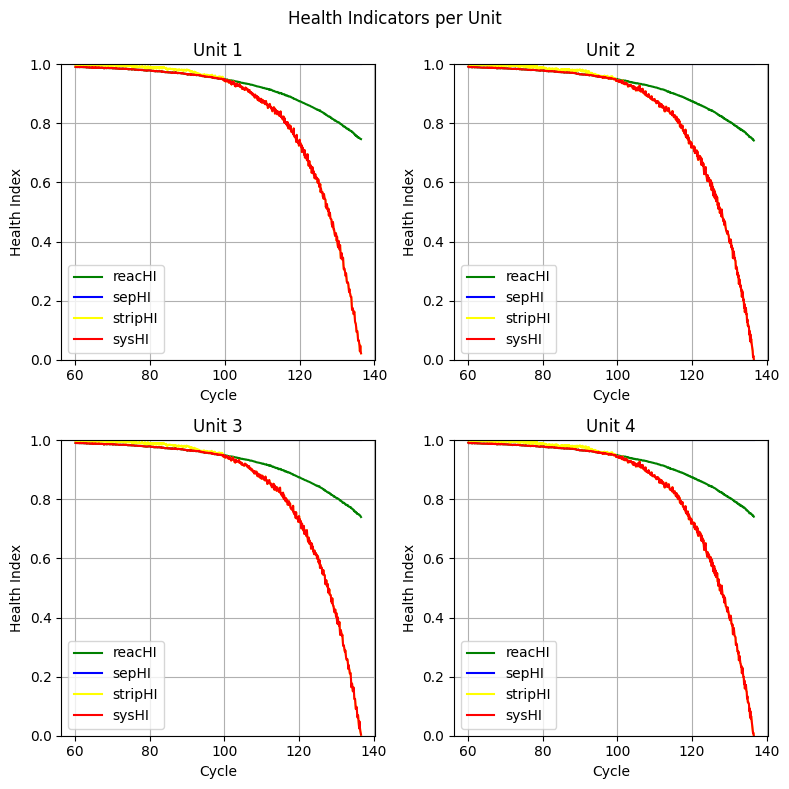

In [16]:
plot1 = MatPlot()
plot1.plot_HI_by_id(
    dfHI,
    hi_columns=["reacHI", "sepHI", "stripHI", "sysHI"],
    num_rows=2,
    num_cols=2,
    colors=['green','blue', 'yellow','red'],
    title="Health Indicators per Unit",
    y_lim=[0, 1]  # adjust if needed
)


In [17]:
# plot1 = MatPlot() 
# plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

In [18]:
# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [rulEnv1["Sys"]], inX=timeDraw,color=['g'], numRow=20, numCol=5)

In [19]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])

#### Environment 3

In [20]:
environmentIdx      = 3
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []
labelRUL            = []
predictRUL         = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # print(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    labelRUL.append(seqXRulTrain[:,-1,:])
    predictRUL.append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:58525||2025-06-11 16:54:59,230-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 1
-------------------------------
(3, 45)
(1295, 1, 45)
(1295, 128, 45)
(1295, 128, 45)
-------------------------------


Process:58525||2025-06-11 16:54:59,653-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


-------------------------------
(3, 45)
(1295, 1, 45)
(1295, 128, 45)
(1295, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1295, 1, 45)
(1295, 128, 45)
(1295, 128, 45)
-------------------------------
Getting the HI at the idx 2
-------------------------------
(3, 45)
(1281, 1, 45)
(1281, 128, 45)
(1281, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1281, 1, 45)
(1281, 128, 45)
(1281, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1281, 1, 45)
(1281, 128, 45)
(1281, 128, 45)
-------------------------------


Process:58525||2025-06-11 16:55:00,080-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 3
-------------------------------
(3, 45)
(1358, 1, 45)
(1358, 128, 45)
(1358, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1358, 1, 45)
(1358, 128, 45)
(1358, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1358, 1, 45)
(1358, 128, 45)
(1358, 128, 45)
-------------------------------


... (190 outputs left out)

Process:58525||2025-06-11 16:55:42,308-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 99
-------------------------------
(3, 45)
(1262, 1, 45)
(1262, 128, 45)
(1262, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1262, 1, 45)
(1262, 128, 45)
(1262, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1262, 1, 45)
(1262, 128, 45)
(1262, 128, 45)
-------------------------------


Process:58525||2025-06-11 16:55:42,796-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 100
-------------------------------
(3, 45)
(1277, 1, 45)
(1277, 128, 45)
(1277, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1277, 1, 45)
(1277, 128, 45)
(1277, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1277, 1, 45)
(1277, 128, 45)
(1277, 128, 45)
-------------------------------


In [21]:
dfHI            = pd.DataFrame()
dfHI["id"]      = np.repeat(np.arange(1, totalTraject + 1), [hiEnv1["Reac"][idx].shape[0] for idx in range(len(hiEnv1["Reac"]))])
dfHI["cycle"]   = np.concatenate(timeDraw).flatten()
dfHI["reacHI"]  = np.concatenate(hiEnv1["Reac"]).flatten()
dfHI["sepHI"]   = np.concatenate(hiEnv1["Sep"]).flatten()
dfHI["stripHI"] = np.concatenate(hiEnv1["Strip"]).flatten()
dfHI["sysHI"]   = np.concatenate(hiEnv1["Sys"]).flatten()
dfHI            = dfHI[dfHI["cycle"] > 60]
# dfHI.to_excel('output.xlsx', index=False)

compMetrics = compute_average_hi_metrics(dfHI, hiCol="reacHI")
print("------------------ Reactor -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sepHI")
print("------------------ Separator -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="stripHI")
print("------------------ Stripper -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sysHI")
print("------------------ System -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

------------------ Reactor -----------------
Average Robustness: 1.0
Average Trendability: nan
Average Monotonicity: 0.0
------------------ Separator -----------------
Average Robustness: 0.4423986
Average Trendability: 0.9162440670141598
Average Monotonicity: 0.864189723320158
------------------ Stripper -----------------
Average Robustness: 0.47265792
Average Trendability: 0.8077263878368609
Average Monotonicity: 0.6989328063241105
------------------ System -----------------
Average Robustness: 0.47371426
Average Trendability: 0.8027768327897017
Average Monotonicity: 0.8146245059288539


In [22]:
rmse_per_unit = [
    np.sqrt(np.mean((tf.squeeze(pred).numpy() - tf.squeeze(label).numpy()) ** 2))
    for pred, label in zip(predictRUL, labelRUL)
]

# Calculate mean RMSE across 100 units
mean_rmse = np.mean(rmse_per_unit)
print("RMSE of RUL predictions:", mean_rmse)


RMSE of RUL predictions: 3.758422111077144


In [23]:
# plot1 = MatPlot()
# plot1.plot_HI_by_id(
#     dfHI,
#     hi_columns=["reacHI", "sepHI", "stripHI", "sysHI"],
#     num_rows=5,
#     num_cols=20,
#     colors=['green','blue', 'yellow','red'],
#     title="Health Indicators per Unit",
#     y_lim=[0, 1]  # adjust if needed
# )


In [24]:
# plot3 = MatPlot() 
# plot3.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX=timeDraw, color=['g','b', 'y','r'], numRow=20, numCol=5)

In [25]:
# plot4 = MatPlot()
# plot4.subPlotMultiImg(inY = [ rulEnv1["Sys"]],  inX=timeDraw, color=['g'], numRow=20, numCol=5)

In [26]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])

#### Environment 4

In [27]:
environmentIdx      = 4
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []
labelRUL            = []
predictRUL         = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  
    # hiReac, binaryMaskReac, probsReac, rulReac               = vaeReac.getHIandRUL(xPredict, comp = "Reac")
    # hiSep, binaryMaskSep,   probsSep, rulSep                 = vaeSep.getHIandRUL(input      = xPredict, comp = "Sep")
    # hiStrip, binaryMaskStrip,probsStrip, rulStrip            = vaeStrip.getHIandRUL(input    = xPredict, comp = "Strip")
    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    # squeezedRulReac                                 = tf.squeeze(rulReac, axis=-1)
    # squeezedRulSep                                  = tf.squeeze(rulSep, axis=-1)
    # squeezedRulStrip                                = tf.squeeze(rulStrip, axis=-1)
    # print(hiMatrixOutput)
    timeDraw.append(seqTimeTrain)
    hiEnv1["Reac"].append(hiReac)
    hiEnv1["Sep"].append(hiSep)
    hiEnv1["Strip"].append(hiStrip)
    hiEnv1["Sys"].append(hiSystem)
    hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    rulEnv1["Sys"].append(predictedRul)
    labelRUL.append(seqXRulTrain[:,-1,:])
    predictRUL.append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

if normalizeHI:
    [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:58525||2025-06-11 16:55:49,437-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 1
-------------------------------
(3, 45)
(1149, 1, 45)
(1149, 128, 45)
(1149, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1149, 1, 45)
(1149, 128, 45)
(1149, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1149, 1, 45)
(1149, 128, 45)
(1149, 128, 45)
-------------------------------


Process:58525||2025-06-11 16:55:49,839-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 2
-------------------------------
(3, 45)
(1151, 1, 45)
(1151, 128, 45)
(1151, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1151, 1, 45)
(1151, 128, 45)
(1151, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1151, 1, 45)
(1151, 128, 45)
(1151, 128, 45)
-------------------------------


Process:58525||2025-06-11 16:55:50,280-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 3
-------------------------------
(3, 45)
(1065, 1, 45)
(1065, 128, 45)
(1065, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1065, 1, 45)
(1065, 128, 45)
(1065, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1065, 1, 45)
(1065, 128, 45)
(1065, 128, 45)
-------------------------------


... (190 outputs left out)

Process:58525||2025-06-11 16:56:31,417-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 99
-------------------------------
(3, 45)
(1100, 1, 45)
(1100, 128, 45)
(1100, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1100, 1, 45)
(1100, 128, 45)
(1100, 128, 45)
-------------------------------


Process:58525||2025-06-11 16:56:31,794-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


-------------------------------
(3, 45)
(1100, 1, 45)
(1100, 128, 45)
(1100, 128, 45)
-------------------------------
Getting the HI at the idx 100
-------------------------------
(3, 45)
(1128, 1, 45)
(1128, 128, 45)
(1128, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1128, 1, 45)
(1128, 128, 45)
(1128, 128, 45)
-------------------------------
-------------------------------
(3, 45)
(1128, 1, 45)
(1128, 128, 45)
(1128, 128, 45)
-------------------------------


In [28]:
dfHI            = pd.DataFrame()
dfHI["id"]      = np.repeat(np.arange(1, totalTraject + 1), [hiEnv1["Reac"][idx].shape[0] for idx in range(len(hiEnv1["Reac"]))])
dfHI["cycle"]   = np.concatenate(timeDraw).flatten()
dfHI["reacHI"]  = np.concatenate(hiEnv1["Reac"]).flatten()
dfHI["sepHI"]   = np.concatenate(hiEnv1["Sep"]).flatten()
dfHI["stripHI"] = np.concatenate(hiEnv1["Strip"]).flatten()
dfHI["sysHI"]   = np.concatenate(hiEnv1["Sys"]).flatten()
# dfHI["reacHI"]  = dfHI["reacHI"].groupby(dfHI["id"]).rolling(256).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["sepHI"]   = dfHI["sepHI"].groupby(dfHI["id"]).rolling(256).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["stripHI"] = dfHI["stripHI"].groupby(dfHI["id"]).rolling(256).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data
# dfHI["sysHI"]   = dfHI["sysHI"].groupby(dfHI["id"]).rolling(256).mean().reset_index(drop=True)  # Apply rolling mean to smooth the data


dfHI            = dfHI[dfHI["cycle"] > 60]
# dfHI.to_excel('output.xlsx', index=False)

compMetrics = compute_average_hi_metrics(dfHI, hiCol="reacHI")
print("------------------ Reactor -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sepHI")
print("------------------ Separator -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="stripHI")
print("------------------ Stripper -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

compMetrics = compute_average_hi_metrics(dfHI, hiCol="sysHI")
print("------------------ System -----------------")
print("Average Robustness:", compMetrics["avg_robustness"])
print("Average Trendability:", compMetrics["avg_trendability"])
print("Average Monotonicity:", compMetrics["avg_monotonicity"])

------------------ Reactor -----------------
Average Robustness: 0.43585837
Average Trendability: 0.9526828578917582
Average Monotonicity: 1.0
------------------ Separator -----------------
Average Robustness: 0.45507932
Average Trendability: 0.8763389779876815
Average Monotonicity: 1.0
------------------ Stripper -----------------
Average Robustness: 0.5264295
Average Trendability: 0.6566084442926424
Average Monotonicity: 0.6745588235294118
------------------ System -----------------
Average Robustness: 0.5222591
Average Trendability: 0.7237885183215
Average Monotonicity: 1.0


In [29]:
rmse_per_unit = [
    np.sqrt(np.mean((tf.squeeze(pred).numpy() - tf.squeeze(label).numpy()) ** 2))
    for pred, label in zip(predictRUL, labelRUL)
]

# Calculate mean RMSE across 100 units
mean_rmse = np.mean(rmse_per_unit)
print("RMSE of RUL predictions:", mean_rmse)


RMSE of RUL predictions: 2.765121825074618


In [30]:
# plot1 = MatPlot()
# plot1.plot_HI_by_id(
#     dfHI,
#     hi_columns=["reacHI", "sepHI", "stripHI", "sysHI"],
#     num_rows=5,
#     num_cols=20,
#     colors=['green','blue', 'yellow','red'],
#     title="Health Indicators per Unit",
#     y_lim=[0, 1]  # adjust if needed
# )


In [31]:
# plot5 = MatPlot() 
# plot1.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

In [32]:
# plot6 = MatPlot()
# plot6.subPlotMultiImg(inY = [rulEnv1["Sys"]], inX=timeDraw, color=['g'], numRow=20, numCol=5)

In [33]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])